# 02. Fashion stores: blocking when the units are heterogeneous

**The decision:** the visual merchandising team designed a new window layout
and wants an answer to one question, a business one: does it raise store sales
enough to become the network standard? The estimation looks trivial, but the
design is not.

**The units:** 120 brick-and-mortar stores, and they are not
interchangeable. A G store sells far more than a PP one regardless of any
window, and the ordering by size (PP < P < M < G) is enormous. If you let
that between-size variation leak into the noise of your test, it drowns the
real effect of the layout. The signal is there, but it sits submerged under
structural noise.

**The chapter's promise:** we will block by store size with `BlockedCRD`,
contrast it against the naive analysis that ignores size, then break the
design on purpose. We will ask what happens when the stores are NOT
independent (interference between units), the assumption the whole design
rests on.

Background theory: [II. Designs](../../../docs/en/theory/02-designs.md)
(topic 5) and [III. Estimation](../../../docs/en/theory/03-estimation.md)
(topic 9).


## The natural reflex (and why it is not enough)

Your usual instinct: stack all treated stores on one side, all controls on
the other, run a t-test on sales, and decide by the p-value. Because
assignment was randomized, that estimator is not even biased. But there are
two hidden problems, of different natures.

**(a) Precision.** A G store dwarfs a PP one: the between-size variance enters
the test's denominator in full and swallows the signal. This is a noise
problem, and blocking fixes it: by randomizing within each size, the
comparison becomes big store against big store, small against small.

**(b) Validity.** The t-test assumes stores do not affect one another. If two
stores share a catchment area and one cannibalizes the other, that assumption
falls, and no gain in precision repairs it. This is a bias problem, not a
noise problem.

We will fix item (a) now, with blocking, and confront item (b) honestly at the
end of the chapter.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd


def _find_data():
    """Locate examples/use_cases/data whether run from the notebook or the root."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base / "data", base / "examples" / "use_cases" / "data"):
            if (cand / "ecommerce_checkout.csv").exists():
                return cand
    raise FileNotFoundError("Could not locate examples/use_cases/data")


DATA = _find_data()

df = pd.read_csv(DATA / "fashion_stores.csv")
# Baseline sales differ strongly by size: this is the between-block variation.
print(df.groupby("store_size")["sales_y0"].mean().round(2))
df.head()

store_size
G     15.70
M     10.18
P      6.23
PP     2.97
Name: sales_y0, dtype: float64


,store_id,region,store_size,foot_traffic_pre,sales_y0,sales_y1
0,1,Sudeste,PP,344.9,3.760,4.160
1,2,Norte,PP,141.7,0.433,0.833
2,3,Sudeste,PP,113.1,3.271,3.671
3,4,Norte,PP,167.8,3.029,3.429
4,5,Sudeste,PP,107.8,4.358,4.758


## The blocked design and balance

`BlockedCRD(block_col="store_size")` randomizes treatment and control within
each store size, forcing balanced proportions in every block. It is the direct
translation of the "compare like with like" reflex into a formal design.

Right after the draw, and before attaching the outcome, it is worth checking
covariate balance with `check_balance`. Randomization should leave treatment
and control similar on `foot_traffic_pre` (pre-treatment foot traffic). Note:
we assess by the magnitude of the SMD (standardized mean difference), not by a
p-value. The rule of thumb is `|SMD| < 0.1` for good balance. A p-value here
would only tell us whether the imbalance is "significant", and that is not the
point: what matters is whether it is small enough not to contaminate the
comparison.


In [2]:
from skxperiments.core.assignment import BlockedAssignment
from skxperiments.design.blocked_crd import BlockedCRD
from skxperiments.design.balance import check_balance

design = BlockedCRD(block_col="store_size", p=0.5, seed=202)
assignment = design.randomize(df[["region", "store_size", "foot_traffic_pre"]].copy())

# Balance is checked on the pre-treatment covariates only.
check_balance(assignment)[["covariate", "smd"]].round(3)

,covariate,smd
0,foot_traffic_pre,-0.032


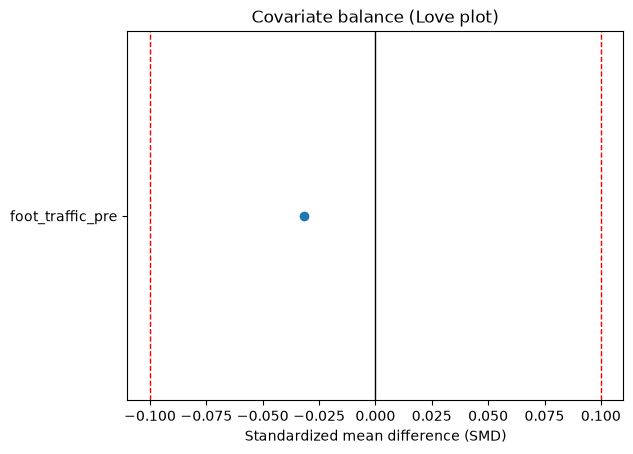

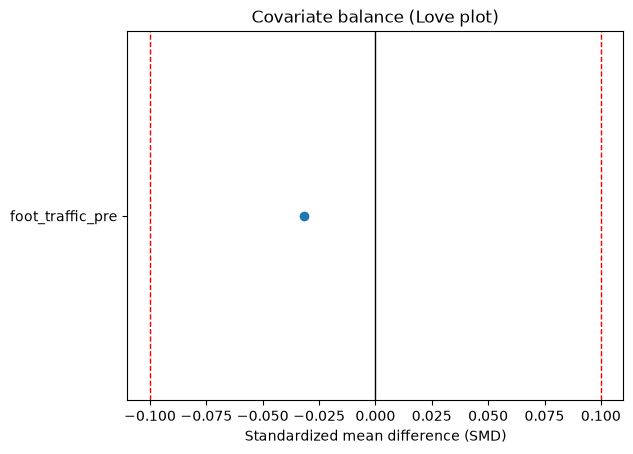

In [3]:
from skxperiments.diagnostics import BalanceReport
from skxperiments.reporting import plot_balance

report = BalanceReport().run(assignment)
ax = plot_balance(report)
ax.set_title("Covariate balance (Love plot)")
ax.figure

## The blocked estimate versus ignoring the blocks

Now we attach the observed outcome and estimate with
`BlockedDifferenceInMeans`: it computes the effect within each block and
returns the size-weighted average of those per-block effects. The interval
comes from `NeymanCI`, using the stratified variance (it sums the per-block
variances rather than mixing the sizes together).

To make the gain explicit, we run the same collected data through the naive
analysis: the same data, but treated as a single CRD, ignoring store size. You
will see the naive standard error come out much larger, because all the
between-size variation re-enters as noise. Same data collection, firmer
decision. That is what blocking buys: on average it does not move the point
estimate, it tightens the interval around it.


In [4]:
from skxperiments.core.assignment import CRDAssignment
from skxperiments.design.crd import CRD
from skxperiments.estimators.blocked_difference_in_means import BlockedDifferenceInMeans
from skxperiments.estimators.difference_in_means import DifferenceInMeans
from skxperiments.inference import NeymanCI

t = assignment.data_[assignment.treatment_col_].to_numpy()
data = assignment.data_.copy()
data["sales"] = np.where(t == 1, df["sales_y1"].to_numpy(), df["sales_y0"].to_numpy())

blocked_a = BlockedAssignment(
    data=data, treatment_col=assignment.treatment_col_, design=design,
    block_col=assignment.block_col_, block_sizes=assignment.block_sizes_, seed=202,
)
blocked_est = BlockedDifferenceInMeans(outcome_col="sales").fit(blocked_a)
blocked = NeymanCI(estimator=BlockedDifferenceInMeans(outcome_col="sales")).fit(blocked_a).estimate()

# Naive: same data, but analyzed as a single CRD (blocks ignored).
naive_a = CRDAssignment(data=data, treatment_col="treatment", design=CRD(p=0.5, seed=202), seed=202)
naive = NeymanCI(estimator=DifferenceInMeans(outcome_col="sales")).fit(naive_a).estimate()

print("per-block ATE:", {k: round(v, 3) for k, v in blocked_est.block_ates_.items()})
pd.DataFrame([
    {"analysis": "Blocked (correct)", "ATE": blocked.ate, "SE": blocked.se,
     "CI_low": blocked.ci[0], "CI_high": blocked.ci[1], "p": blocked.p_value},
    {"analysis": "Naive CRD (blocks ignored)", "ATE": naive.ate, "SE": naive.se,
     "CI_low": naive.ci[0], "CI_high": naive.ci[1], "p": naive.p_value},
]).round(3)

per-block ATE: {'G': 0.091, 'M': 0.534, 'P': 0.735, 'PP': 0.971}


,analysis,ATE,SE,CI_low,CI_high,p
0,Blocked (correct),0.583,0.219,0.153,1.013,0.008
1,Naive CRD (blocks ignored),0.583,0.901,-1.182,2.348,0.518


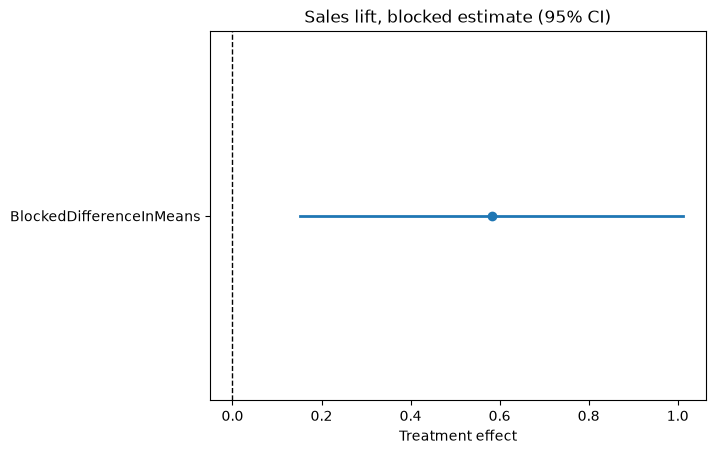

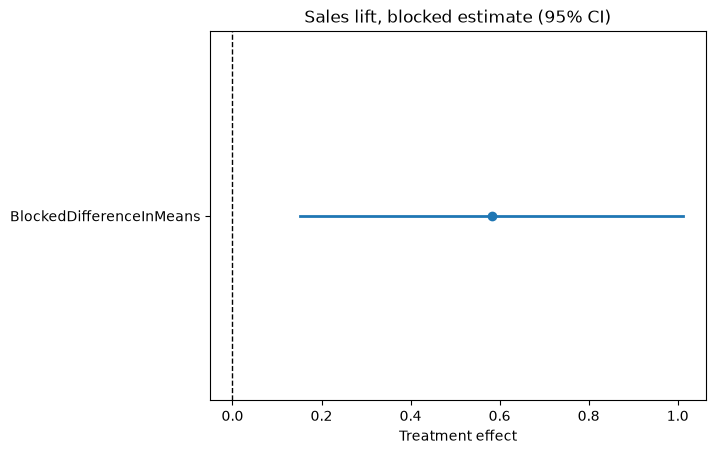

In [5]:
from skxperiments.reporting import plot_effect

ax = plot_effect(blocked)
ax.set_title("Sales lift, blocked estimate (95% CI)")
ax.figure

## Breaking the test: interference and SUTVA

Everything in the design so far rests on one load-bearing assumption: each
store's outcome depends only on its OWN assignment. This is the heart of SUTVA
(the Stable Unit Treatment Value Assumption): no interference between units.

When it holds, the treated-versus-control contrast measures the effect of the
layout. When it falls, the number lies. Picture a treated store, with the new
window, pulling customers from a nearby control store in the same catchment
area. The controls get artificially depressed, and the difference in means
OVERSTATES the true effect, because part of the treatment's "gain" is really
loss stolen from control.

We will simulate a growing leak (spillover) between neighbors and watch the
bias appear in a controlled way.


In [6]:
# SUTVA stress test: what if a treated store pulls customers from a nearby control store?
# Then control sales are depressed by treatment, and the naive difference in means
# OVERSTATES the true effect. skxperiments (like any unit-level design) assumes this
# does NOT happen. We simulate growing spillover and watch the bias appear.
def spillover_demo(leaks, n=120, tau=0.40, reps=400, rng=None):
    rng = rng or np.random.default_rng(202)
    rows = []
    for leak in leaks:
        dims = []
        for _ in range(reps):
            y0 = rng.normal(10.0, 3.0, size=n)
            t = (rng.random(n) < 0.5).astype(int)
            y_obs = np.where(t == 1, y0 + tau, y0 - leak)   # controls lose `leak` to treated neighbors
            dims.append(y_obs[t == 1].mean() - y_obs[t == 0].mean())
        m = float(np.mean(dims))
        rows.append({"spillover_leak": leak, "mean_naive_ATE": round(m, 3),
                     "true_ATE": tau, "bias": round(m - tau, 3)})
    return pd.DataFrame(rows)


spillover_demo([0.0, 0.2, 0.4, 0.6])

,spillover_leak,mean_naive_ATE,true_ATE,bias
0,0.0,0.416,0.4,0.016
1,0.2,0.622,0.4,0.222
2,0.4,0.809,0.4,0.409
3,0.6,0.971,0.4,0.571


### The library's honest limit (and what to use instead)

Read the table from the bottom up. With no leak (`leak` 0.0) the bias is ~0:
SUTVA holds and the naive estimate lands near the true 0.40. As the leak grows,
the bias grows almost one-for-one: at `leak` 0.6 the naive estimate reads
~0.97, more than double the real effect of 0.40. And note the most
uncomfortable point: blocking does NOT save you here, because interference is a
validity problem, not a precision one. Tightening the interval around a biased
number just gives you more confidence in the wrong answer.

`skxperiments` v1 assumes unit-level SUTVA and has NO cluster-randomized or geo
design. If your units can interfere (stores sharing one mall, users in one
social graph), you must randomize at the level where interference stops: whole
malls or regions as units, even if it costs statistical power. Cluster and geo
designs are out of scope in v1 and on the roadmap. Name this openly: the
library gives you no guardrail against interference, so the reasoning about it
is yours to do.


## Decision, limits, and next step

**The decision.** The true effect is +0.40 (thousands in daily sales),
recovered by the blocked estimate, whose interval excludes zero and whose
standard error sits far below the naive one. Recommendation: roll out the new
layout across the network, PROVIDED the stores behave as independent units.

**This chapter's limits.**
1. SUTVA and interference: the assumption behind every unit-level design we use
   here. If it falls, the number lies and the design does not warn you.
2. Blocking buys precision, not validity: it tightens the interval, but it does
   not fix interference or any other source of bias.
3. The built-in `power_analysis` covers only two-arm continuous outcomes, not
   blocked designs. Sizing a blocked study is still done by hand.

**Next step:** [03. Factorial campaign](03_fintech_factorial.ipynb), where we
move from one factor to two and learn to read interactions.
